In [2]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models
import optimizers

if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')
print(device)

cuda:0


In [2]:
s3d_or_vit = 'vit'

In [3]:
labels = pd.read_csv("../../labels/semi_cleaned_labels_3_features_2024-10-21.csv")
labels = labels.drop(columns=['MRN','SURGERY_DATE'])

new_labels = labels.replace('nan', np.nan)
new_labels = new_labels.replace('nc', np.nan)

# drop nans:
new_labels.dropna(inplace=True) # needs to happen before sorting into pre and post

new_labels_pre = new_labels[['ACC_NUM','LVEF_pre','RVSF_pre','TR_pre']]
new_labels_pre.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_pre['prepost'] = 0

new_labels_post = new_labels[['ACC_NUM','LVEF_post','RVSF_post','TR_post']]
new_labels_post.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_post['prepost'] = 1

new_labels = pd.concat([new_labels_pre, new_labels_post])
new_labels.reset_index(drop=True, inplace=True)

new_labels['LVEF'] = new_labels['LVEF'].astype(float)/100
new_labels['RVSF'] = new_labels['RVSF'].astype(float)/6
new_labels['TR'] = new_labels['TR'].astype(float)/7

ground_truths = pd.read_csv("../../labels/500_reports_groundtruth.csv")['ACC_NUM']

# drop nans:
new_labels.dropna(inplace=True)

ground_truths = list(ground_truths.astype(float))

training_labels = new_labels.drop(new_labels[new_labels['ACC_NUM'].isin(ground_truths)].index)
evaluation_labels = new_labels.drop(new_labels[~new_labels['ACC_NUM'].isin(ground_truths)].index) # not quite correct, but probably good enough until we clean the gt dataset

print(len(training_labels), len(evaluation_labels))

11120 842


/tmp/ipykernel_1373288/1912813610.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_pre['prepost'] = 0
/tmp/ipykernel_1373288/1912813610.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_post['prepost'] = 1


In [4]:
view_prediction_csvs = glob.glob("../../labels/view_predictions/cycle_*/predictions_all_cycle_*.csv", recursive=True)
predictions = []
for cycle_preds in view_prediction_csvs:
    cycle = pd.read_csv(cycle_preds)
    # predictions.append(cycle.loc[cycle['prediction'].isin([3,4,5,6,7,8,9])]) # If filtering by view - currently all 2,4,5 chamber with/without color
    predictions.append(cycle) # If not filtering by view

all_cycles = pd.concat(predictions)
all_cycles = all_cycles.reset_index()
val_cycles = all_cycles.sample(frac=0.01, random_state=0)
train_cycles = all_cycles.drop(val_cycles.index)

val_cycles = val_cycles.reset_index()
train_cycles = train_cycles.reset_index()
test_cycles = train_cycles.copy()

In [5]:
removals = []
for i in tqdm.tqdm(range(len(test_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(test_cycles['clip_path'].iloc[i])[0])) not in list(evaluation_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
test_cycles = test_cycles.drop(removals)
print(len(test_cycles))
test_cycles = test_cycles.reset_index(drop=True)

  0%|          | 0/586490 [00:00<?, ?it/s]

100%|██████████| 586490/586490 [00:23<00:00, 25435.89it/s]

35668


In [6]:
test_clips = list(test_cycles['clip_path'])

In [7]:
prepost_pred = pd.read_csv('/home/trevor/repos/deep_TEE/labels/preop_postop_prediction.csv')
acc_nums = [prepost_pred['clip_path'][i].split('/')[0] if type(prepost_pred['clip_path'][i])==str else '' for i in range(len(prepost_pred['clip_path']))]
dcm_nums = [prepost_pred['clip_path'][i].split('/')[-1] if type(prepost_pred['clip_path'][i])==str else ''  for i in range(len(prepost_pred['clip_path']))]
prepost_pred['ACC_NUM'] = acc_nums
prepost_pred['DCM_NUM'] = dcm_nums

In [8]:
if s3d_or_vit == 's3d':
    test_transforms = datasets.TransformsComposed('valtest', size=(224,224))
elif s3d_or_vit == 'vit':
    test_transforms = datasets.TransformsComposed('valtest', size=(128,128))

In [9]:
features = ['LVEF','RVSF','TR']

In [10]:
test_dataset = datasets.VideoDataset(clip_paths=test_clips, labels_df=evaluation_labels, features=features, time_df=prepost_pred, transform=test_transforms, duration=32, skip=2)

# Evaluation

In [11]:
import json
log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/log.json', 'r'))
# log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_anyview_test1/log.json', 'r'))

(0.00025, 0.0005)

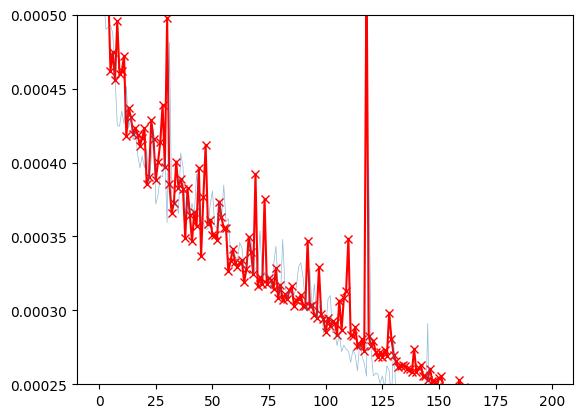

In [12]:
# plt.plot(np.array(log['tick']), log['loss'], linewidth=0.5, alpha=0.5)
# plt.scatter([log['tick'][i] for i,j in enumerate(log['valloss']) if not np.isnan(j)], [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
plt.plot( [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
plt.plot(log['loss'][::25], linewidth=0.5, alpha=0.5)
plt.gca().set_ylim([0.00025,0.0005])

(0.0001, 0.0007)

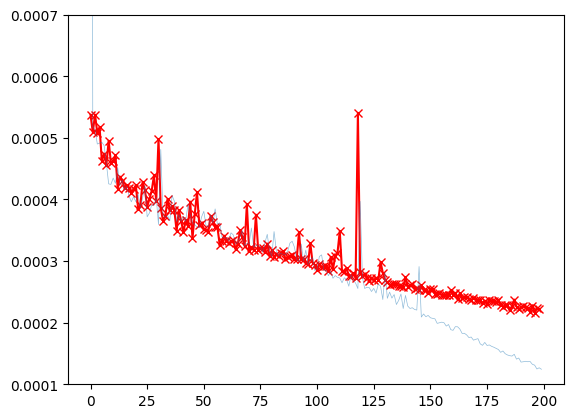

In [13]:
# plt.plot(np.array(log['tick']), log['loss'], linewidth=0.5, alpha=0.5)
# plt.scatter([log['tick'][i] for i,j in enumerate(log['valloss']) if not np.isnan(j)], [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
plt.plot( [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
plt.plot(log['loss'][::25], linewidth=0.5, alpha=0.5)
plt.gca().set_ylim([0.0001,0.0007])

In [14]:
print(min([i for i in log['valloss'] if not np.isnan(i)]), np.where(np.array([i for i in log['valloss'] if not np.isnan(i)])==min([i for i in log['valloss'] if not np.isnan(i)])))

0.00021634696167893708 (array([196]),)


In [15]:
np.array([i for i in log['valloss'] if not np.isnan(i)])[100]

0.0002852467878255993

In [17]:
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/*.pt'))[196])['net'].to(device).eval()
model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/*.pt'))[100])['net'].to(device).eval()

# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_anyview_test1/*.pt'))[62])['net'].to(device).eval()

In [18]:
# Visualize the images
idx = np.random.randint(len(test_dataset))
parcel = test_dataset[idx]['data']

with torch.no_grad():
    print(model(test_dataset[idx]['data'].unsqueeze(0).to(device)))
    print(test_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

NameError: name 'test_dataset' is not defined

## No Aggregation

In [23]:
y = []
yp = []
maxsample = 1000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        y.append(test_dataset[idx]['label'].numpy().squeeze())
        yp.append(model(test_dataset[idx]['data'].unsqueeze(0).to(device)).cpu().numpy().squeeze())
       
results = np.concatenate((np.array(y),np.array(yp)), axis=1)
df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

100%|██████████| 1000/1000 [02:36<00:00,  6.40it/s]


Text(0.45, 0, "Pearson's r = 0.22")

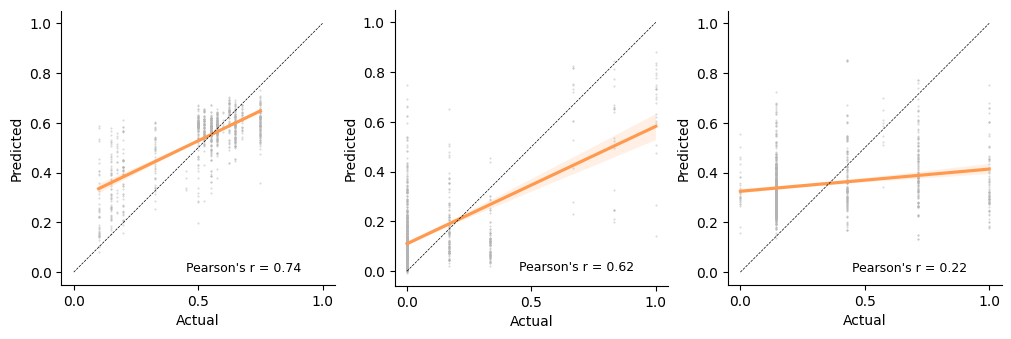

In [19]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.29")

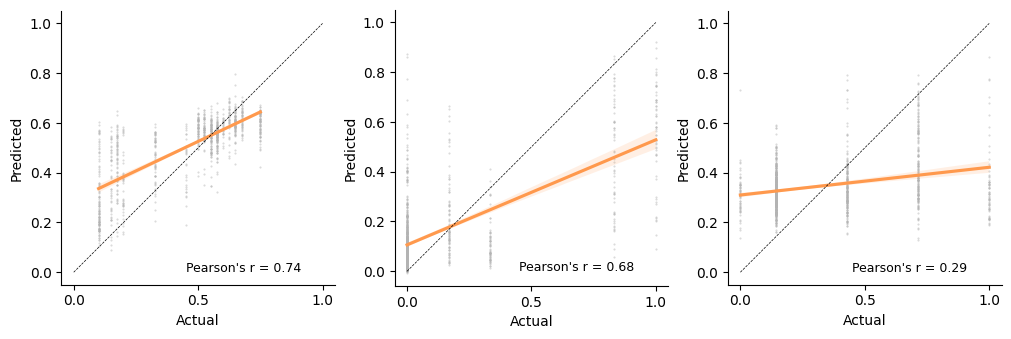

In [24]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

## Aggregation over a clip

In [20]:
class EvaluationDataset(torch.utils.data.Dataset):

    def __init__(self, clips, labels=None, transform=None, duration=32, skip=1, autobatch=True):
        self.clips = clips
        self.transform = transform
        self.duration = duration
        self.skip = skip
        self.autobatch = autobatch
        self.labels = labels

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        data = self.__read_images(self.clips[idx], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(0,2,1,3,4) # reshape to (B,C,T,H,W)
        
        if self.labels:
            label = labels[idx]
            return {'data':data, 'label':label}
        else:
            return {'data':data}
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')
        if not self.autobatch:
            if len(frame_paths) <= duration * skip:
                start = 0
                stop = len(frame_paths)
                pad = (duration * skip - stop) // skip
            else:
                start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
                stop = start + duration * skip
                pad = 0
            frames = []
            for frame in sorted(frame_paths)[start:stop:skip]:
                frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
            for i in range(pad):
                frames.append(torch.zeros_like(frames[-1]))
            frames = torch.stack(frames, dim=0)
            batches = frames
        else:
            batches = []
            for batch in range(int(np.ceil(len(frame_paths)/skip/duration))):
                start = batch * skip * duration
                stop = min((batch + 1) * skip * duration, len(frame_paths))
                pad = min(0, len(frame_paths) - ((batch + 1) * skip * duration))
                
                frames = []
                for frame in sorted(frame_paths)[start:stop:skip]:
                    frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
                for i in range(-pad//2):
                    frames.append(torch.zeros_like(frames[-1]))
                frames = torch.stack(frames, dim=0)
                batches.append(frames)
            batches = torch.stack(batches, dim=0)
        return batches

In [21]:
paths = [test_dataset.clip_paths[i] for i in range(len(test_dataset))]
labels = [test_dataset[i]['label'] for i in range(len(test_dataset))]

In [22]:
eval_dataset = EvaluationDataset(paths, labels=labels, transform=test_transforms, duration=32, skip=2, autobatch=True)

In [23]:
# y = []
# yp = []
# maxsample = 10000

# with torch.no_grad():
#     for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
#         y.append(eval_dataset[idx]['label'])
#         yp.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
# df = pd.DataFrame({'y':y, 'yp':yp})

In [24]:
y = []
yp = []
maxsample = 10000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        # if test_dataset[idx]['label'] != test_dataset[idx]['label']:
        #     continue
        # if test_dataset[idx]['label'] > 1:
        #     continue
        y.append(eval_dataset[idx]['label'].numpy().squeeze())
        # yp.append(model(eval_dataset[idx]['data'].unsqueeze(0).to(device)).cpu().numpy().squeeze())
        yp.append(model(eval_dataset[idx]['data'].to(device)).cpu().numpy().squeeze())
       
results = np.concatenate((np.array(y),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in yp])), axis=1)

df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

df = df.drop(np.where(df['LVEF_label'] > 1)[0])

100%|██████████| 10000/10000 [09:12<00:00, 18.11it/s]


In [25]:
# fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
# for a in ax:
#     a.spines[['right', 'top']].set_visible(False)
#     a.set_aspect('equal')
#     a.set_xticks([0,0.5,1])

# from scipy import stats
# res = stats.pearsonr(y, yp)
# sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
# ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[0].set_aspect('equal')
# ax[0].set_ylabel('Predicted')
# ax[0].set_xlabel('Actual')
# ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.30")

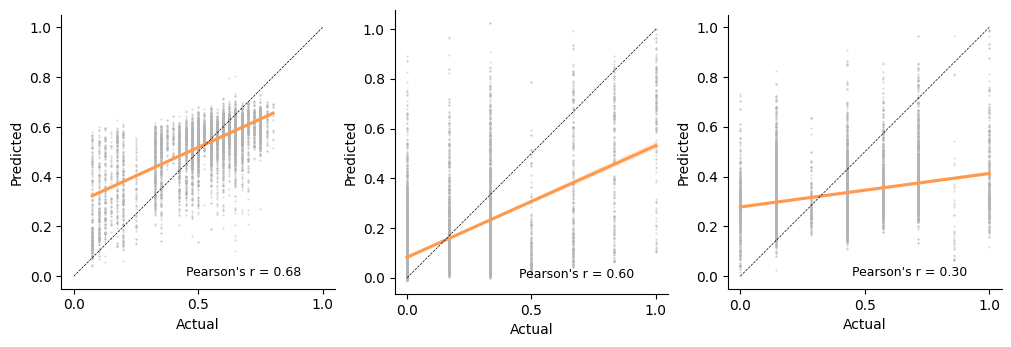

In [26]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

## Aggregation over an entire study

In [158]:
# Aggregation over time for a study

y = []
yp = []
maxsample = 10000
running_pred = []
running_label = []
curr_acc = os.path.basename(os.path.split(eval_dataset.clips[0])[0])

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
        acc = os.path.basename(os.path.split(eval_dataset.clips[idx])[0])
        if acc != curr_acc:
            # print(running_label)
            # print(running_pred)
            y.append(running_label)
            yp.append(running_pred)
            running_pred = []
            running_label = []
            curr_acc = acc
            # print(running_label)
            # print(running_pred)
            # break
        
        running_pred.append(model(eval_dataset[idx]['data'].to(device)).cpu().numpy())
        running_label.append(eval_dataset[idx]['label'].numpy())
        # print(running_pred)
        # print(running_label)
        # break
        
# ymean = []
# ypmean = []
# for i in range(len(yp)):
#     ymean.append(np.mean(np.array(y[i]), axis=0))
#     for j in yp[i]:
#         if j.shape != (3,):
#             yp[i] = np.mean(j, axis=0)
#     ypmean.append(np.mean(np.array(yp[i]), axis=0))

# results = np.concatenate((np.array(ymean),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in ypmean])), axis=1)
# df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

df = df.drop(np.where(df['LVEF_label'] > 1)[0])

100%|██████████| 10000/10000 [09:20<00:00, 17.84it/s]


In [159]:
testyp = yp.copy()
testy = y.copy()

In [160]:
ymean = []
ypmean = []
for i in range(len(testyp)):
    ymean.append(np.array(testy[i][0]))
    print(f'Processing study {i}')
    prediction = np.zeros((3,))
    for j in range(len(testyp[i])):
        for k in range(len(testyp[i][j])):
            prediction = prediction + np.array(testyp[i][j][k])
    ypmean.append(prediction / len(testyp[i][j]))

results = np.concatenate((np.array(ymean).squeeze(),np.array(ypmean)), axis=1)
df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

Processing study 0
Processing study 1
Processing study 2
Processing study 3
Processing study 4
Processing study 5
Processing study 6
Processing study 7
Processing study 8
Processing study 9
Processing study 10
Processing study 11
Processing study 12
Processing study 13
Processing study 14
Processing study 15
Processing study 16
Processing study 17
Processing study 18
Processing study 19
Processing study 20
Processing study 21
Processing study 22
Processing study 23
Processing study 24
Processing study 25
Processing study 26
Processing study 27
Processing study 28
Processing study 29
Processing study 30
Processing study 31
Processing study 32
Processing study 33
Processing study 34
Processing study 35
Processing study 36
Processing study 37
Processing study 38
Processing study 39
Processing study 40
Processing study 41
Processing study 42
Processing study 43
Processing study 44
Processing study 45
Processing study 46
Processing study 47
Processing study 48
Processing study 49
Processing

Text(0.5, 1.0, 'TR')

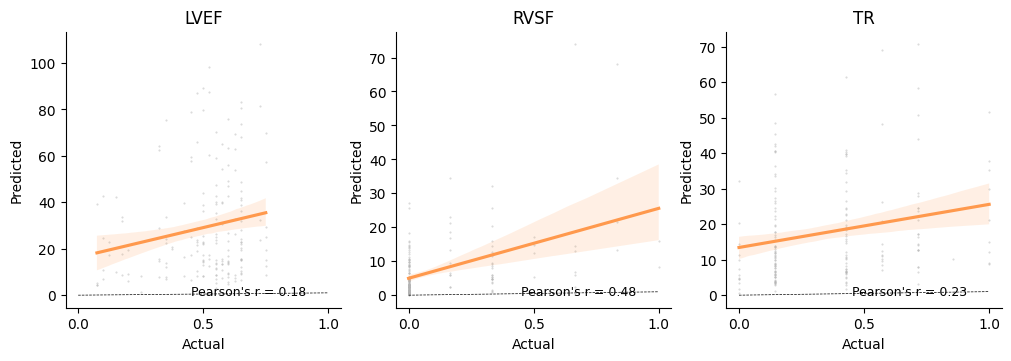

In [162]:
fig, ax = plt.subplots(1,3, figsize=(10,3.5), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    # a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[0].set_title('LVEF')

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[1].set_title('RVSF')

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[2].set_title('TR')

/home/trevor/repos/deep_TEE/data/semi-processed/unsupervised/train/44822887/1.2.840.113663.1500.1.458631247.3.24.20220609.94709.700.dcm
tensor([[0.6030, 0.0279, 0.2703]], device='cuda:1')
tensor([[0.5250, 0.0000, 0.1429]], dtype=torch.float64)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


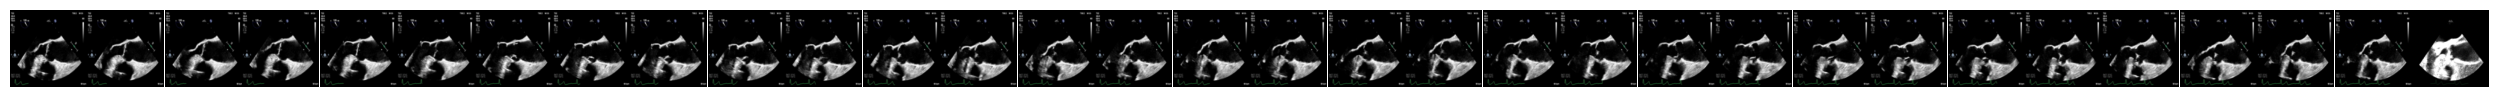

In [226]:
# Visualize the images
idx = np.random.randint(len(test_dataset))
parcel = test_dataset[idx]['data']
print(test_dataset.clip_paths[idx])

with torch.no_grad():
    print(model(test_dataset[idx]['data'].unsqueeze(0).to(device)))
    print(test_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))